In [2]:
import torch
import math
import numpy as np
from dataclasses import dataclass

import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# ============================================================
# 1. Define a tiny config so we can see everything clearly
# ============================================================
@dataclass
class TinyConfig:
    n_embd: int = 8       # embedding dimension (kept tiny!)
    n_head: int = 2        # number of attention heads
    block_size: int = 6    # max sequence length

config = TinyConfig()
print(f"n_embd={config.n_embd}, n_head={config.n_head}, head_size={config.n_embd // config.n_head}, block_size={config.block_size}")


n_embd=8, n_head=2, head_size=4, block_size=6


In [3]:
# ============================================================
# 2. Define the CausalSelfAttention class (same as yours)
# ============================================================
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                            .view(1, 1, config.block_size, config.block_size))
        
    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)  # fix: split along dim=2
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y

In [4]:
# ============================================================
# 3. Create the module and a toy input
# ============================================================
torch.manual_seed(42)
attn = CausalSelfAttention(config)
attn.eval()

B, T, C = 1, 4, config.n_embd   # 1 batch, 4 tokens, 8-dim embeddings
x = torch.randn(B, T, C)

print(f"\nInput x shape: {x.shape}  (B={B}, T={T}, C={C})")
print(f"Input x:\n{x.squeeze(0).detach().numpy().round(2)}")



Input x shape: torch.Size([1, 4, 8])  (B=1, T=4, C=8)
Input x:
[[ 0.97 -1.02 -0.54 -0.44 -0.31 -0.13 -0.71 -0.05]
 [ 2.02  0.25  0.94  0.71 -0.03  0.1   1.34  0.71]
 [ 0.4  -0.71  0.83 -0.96  0.45  1.25 -2.31 -1.29]
 [ 0.18 -2.13 -0.13 -1.04 -0.76 -0.06  1.2  -0.98]]


## 1.0 Visualization of the Transfomer Decoder Layers

In [5]:
# ============================================================
# 1. Define a tiny config so we can see everything clearly
# ============================================================
@dataclass
class TinyConfig:
    n_embd: int = 8       # embedding dimension (kept tiny!)
    n_head: int = 2        # number of attention heads
    block_size: int = 6    # max sequence length

config = TinyConfig()
print(f"n_embd={config.n_embd}, n_head={config.n_head}, head_size={config.n_embd // config.n_head}, block_size={config.block_size}")

# ============================================================
# 2. Define the CausalSelfAttention class (same as yours)
# ============================================================
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                            .view(1, 1, config.block_size, config.block_size))
        
    def forward(self, x):
        B, T, C = x.size()
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)  # fix: split along dim=2
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        y = self.c_proj(y)
        return y

n_embd=8, n_head=2, head_size=4, block_size=6


In [6]:
# Create the module and a toy output
torch.manual_seed
attn = CausalSelfAttention(config)
attn.eval()

B, T, C = 1, 4, config.n_embd # 1 batch, 4 tokens, 8-dim embeddings
x = torch.randn(B, T, C)

print(f"\nInput x shape: {x.shape}  (B={B}, T={T}, C={C})")
print(f"Input x:\n{x.squeeze(0).detach().numpy().round(2)}")




Input x shape: torch.Size([1, 4, 8])  (B=1, T=4, C=8)
Input x:
[[-1.87  2.33 -0.92  0.67 -0.44 -2.32  1.29  0.22]
 [-0.85  1.65  1.6  -0.08  0.43  0.37  0.76  1.18]
 [-0.41  0.52 -0.7  -0.43  0.14  0.07  0.56 -0.58]
 [-1.08 -0.39  0.81  1.5   0.04  1.44  0.23  0.51]]



After c_attn -> qkv shape: torch.Size([1, 4, 24])
After split   -> q:torch.Size([1, 4, 8]), k:torch.Size([1, 4, 8]), v:torch.Size([1, 4, 8])

Multi-head shapes -> q:torch.Size([1, 2, 4, 4]), k:torch.Size([1, 2, 4, 4]), v:torch.Size([1, 2, 4, 4])
  (B=1, n_head=2, T=4, head_size=4)


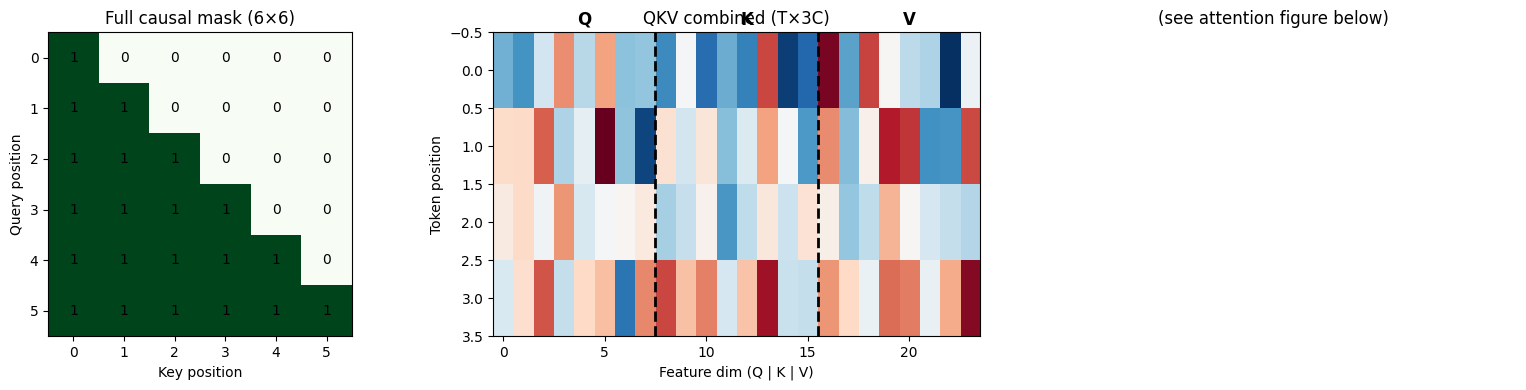

In [7]:
# ============================================================
# 4. Step-by-step forward pass with visualizations
# ============================================================

# --- 4a. The causal mask (bias buffer) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

mask_full = attn.bias.squeeze().numpy()

# plt components
axes[0].imshow(mask_full, cmap='Greens', vmin=0, vmax=1)
axes[0].set_title(f"Full causal mask ({config.block_size}×{config.block_size})")
axes[0].set_xlabel("Key position")
axes[0].set_ylabel("Query position")

for i in range(config.block_size):
    for j in range(config.block_size):
        axes[0].text(j, i, f"{int(mask_full[i,j])}", ha='center', va='center', fontsize=10)

# --- 4b. c_attn: project to Q, K, V ---
qkv = attn.c_attn(x) # B, T, 3*C
q, k, v_proj = qkv.split(config.n_embd, dim=2) # each (B, T, C)

print(f"\nAfter c_attn -> qkv shape: {qkv.shape}")
print(f"After split   -> q:{q.shape}, k:{k.shape}, v:{v_proj.shape}")

# Show QKV as heatmaps
qkv_np = qkv.squeeze(0).detach().numpy()
axes[1].imshow(qkv_np, cmap='RdBu', aspect='auto')
axes[1].set_title("QKV combined (T×3C)")
axes[1].set_xlabel("Feature dim (Q | K | V)")
axes[1].set_ylabel("Token position")
axes[1].axvline(x=C-0.5, color='black', linewidth=2, linestyle='--')
axes[1].axvline(x=2*C-0.5, color='black', linewidth=2, linestyle='--')
axes[1].text(C//2, -0.6, "Q", ha='center', fontsize=12, fontweight='bold')
axes[1].text(C + C//2, -0.6, "K", ha='center', fontsize=12, fontweight='bold')
axes[1].text(2*C + C//2, -0.6, "V", ha='center', fontsize=12, fontweight='bold')

# --- 4c. Reshape into multi-head form ---
nh = config.n_head
hs = C // nh # each head only looks at a subset of the features

k_mh = k.view(B, T, nh, hs).transpose(1, 2)   # (B, nh, T, hs)
q_mh = q.view(B, T, nh, hs).transpose(1, 2)
v_mh = v_proj.view(B, T, nh, hs).transpose(1, 2)

print(f"\nMulti-head shapes -> q:{q_mh.shape}, k:{k_mh.shape}, v:{v_mh.shape}")
print(f"  (B={B}, n_head={nh}, T={T}, head_size={hs})")

# --- 4d. Attention scores (before mask, after mask, after softmax) ---
att_raw = (q_mh @ k_mh.transpose(-2, -1)) * (1.0 / math.sqrt(hs))
att_masked = att_raw.clone()
att_masked = att_masked.masked_fill(attn.bias[:,:,:T,:T] == 0, float('-inf'))
att_soft = F.softmax(att_masked, dim = -1)

# Remove the plot placeholder and make a new figure
axes[2].axis('off')
axes[2].set_title("(see attention figure below)")
plt.tight_layout()
plt.show()

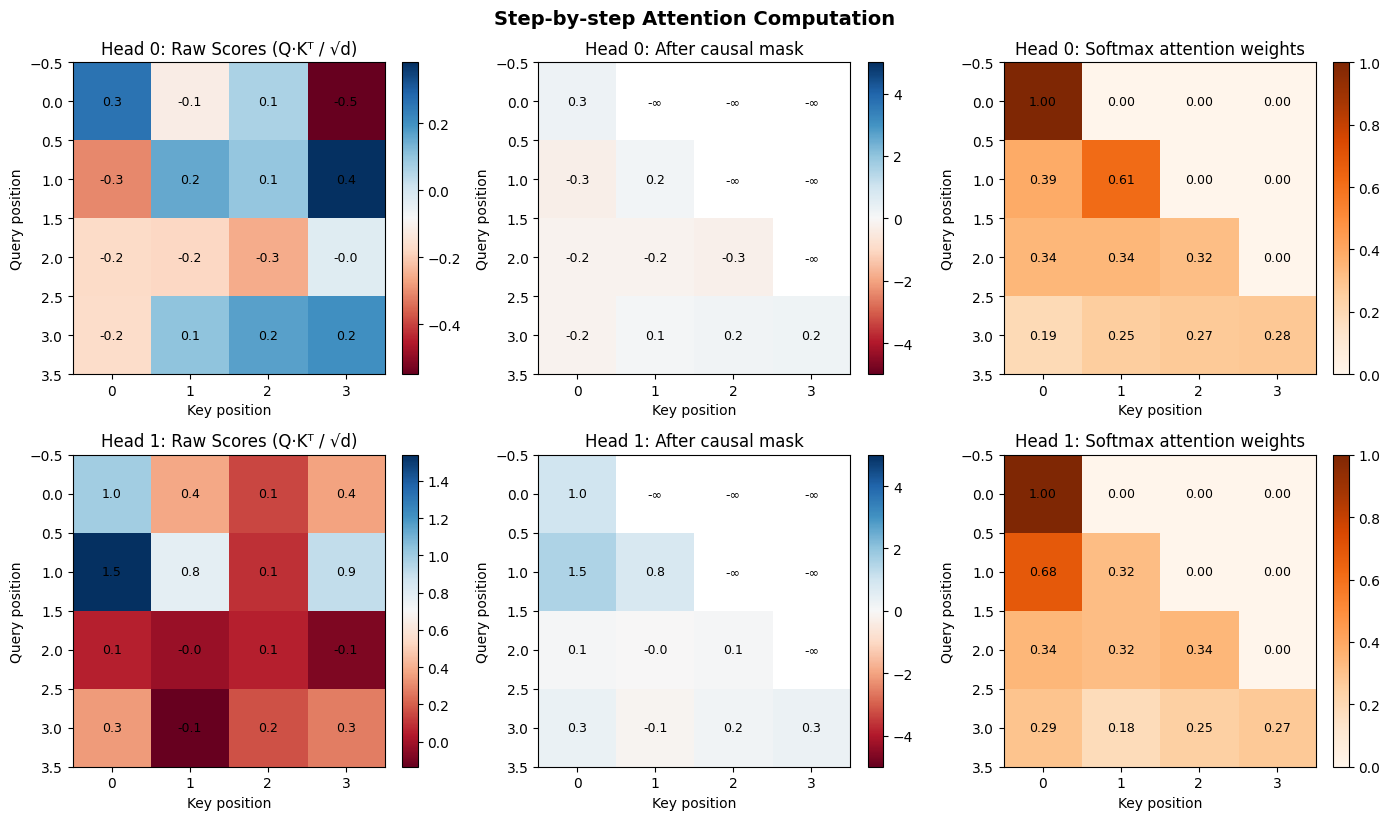

In [9]:
# Detailed attention figure: one row per head
fig2, axes2 = plt.subplots(nh, 3, figsize=(14, 4*nh))
if nh == 1:
    axes2 = axes2[np.newaxis, :]

for h in range(nh):
    raw = att_raw[0, h].detach().numpy()
    masked = att_masked[0, h].detach().numpy()
    soft = att_soft[0, h].detach(). numpy()

    im0 = axes2[h, 0].imshow(raw, cmap='RdBu', aspect='auto')
    axes2[h, 0].set_title(f"Head {h}: Raw Scores (Q·Kᵀ / √d)")
    plt.colorbar(im0, ax=axes2[h, 0], fraction=0.046)
    for i in range(T):
        for j in range(T):
            axes2[h, 0].text(j, i, f"{raw[i,j]:.1f}", ha="center", va="center", fontsize=9)
    
    im1 = axes2[h, 1].imshow(masked, cmap='RdBu', aspect='auto', vmin=-5, vmax=5)
    axes2[h,1].set_title(f"Head {h}: After causal mask")
    plt.colorbar(im1, ax=axes2[h, 1], fraction=0.046)
    for i in range(T):
        for j in range(T):
            val = masked[i,j]
            txt = "-∞" if val == float('-inf') else f"{val:.1f}"
            axes2[h, 1].text(j, i, txt, ha='center', va='center', fontsize=9)
    
    im2 = axes2[h, 2].imshow(soft, cmap='Oranges', aspect='auto', vmin=0, vmax=1)
    axes2[h, 2].set_title(f"Head {h}: Softmax attention weights")
    plt.colorbar(im2, ax=axes2[h, 2], fraction=0.046)
    for i in range(T):
        for j in range(T):
            axes2[h, 2].text(j, i, f"{soft[i,j]:.2f}", ha='center', va='center', fontsize=9)

for ax_row in axes2:
    for ax in ax_row:
        ax.set_xlabel("Key position")
        ax.set_ylabel("Query position")
plt.tight_layout()
plt.suptitle("Step-by-step Attention Computation", y=1.02, fontsize=14, fontweight='bold')
plt.show()


After att @ V -> shape: torch.Size([1, 2, 4, 4])


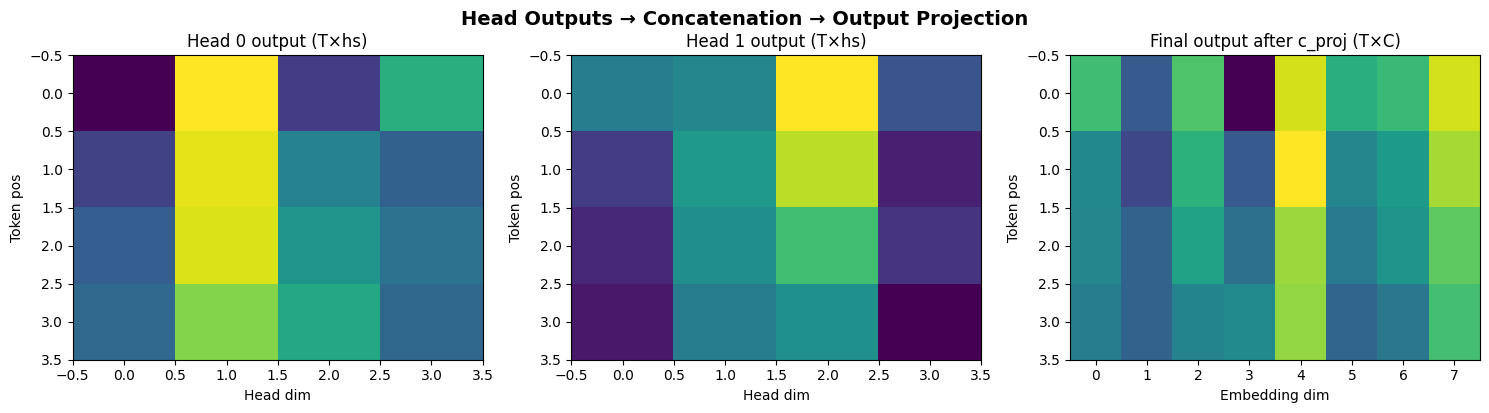

In [11]:
# --- 4e. Weighted sum: att @ V ---
y_heads = att_soft @ v_mh # (B, nh, T, hs)
print(f"\nAfter att @ V -> shape: {y_heads.shape}")

fig3, axes3 = plt.subplots(1, nh+1, figsize=(5*(nh+1), 4))
for h in range(nh):
    data = y_heads[0, h].detach().numpy()
    axes3[h].imshow(data, cmap='viridis', aspect='auto')
    axes3[h].set_title(f"Head {h} output (T×hs)")
    axes3[h].set_xlabel("Head dim")
    axes3[h].set_ylabel("Token pos")

# --- 4f. Concatenate heads and apply output projection ---
y_concat = y_heads.transpose(1, 2).contiguous().view(B, T, C)
y_out = attn.c_proj(y_concat)

concat_np = y_concat.squeeze(0).detach().numpy()
out_np = y_out.squeeze(0).detach().numpy()

axes3[nh].imshow(out_np, cmap='viridis', aspect='auto')
axes3[nh].set_title(f"Final output after c_proj (T×C)")
axes3[nh].set_xlabel("Embedding dim")
axes3[nh].set_ylabel("Token pos")
plt.tight_layout()
plt.suptitle("Head Outputs → Concatenation → Output Projection", y=1.02, fontsize=14, fontweight='bold')
plt.show()


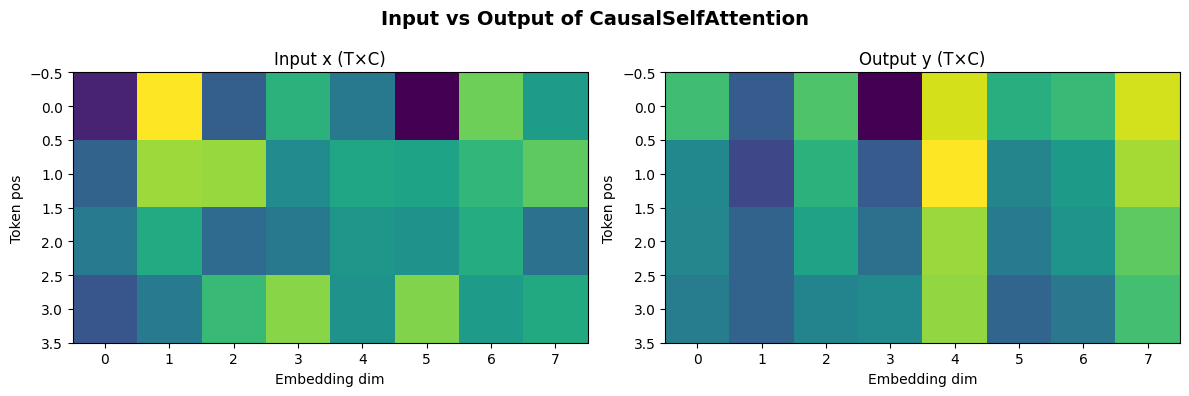

In [12]:
# --- 4g. Compare input vs output ---
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 4))
axes4[0].imshow(x.squeeze(0).detach().numpy(), cmap='viridis', aspect='auto')
axes4[0].set_title("Input x (T×C)")
axes4[0].set_xlabel("Embedding dim")
axes4[0].set_ylabel("Token pos")

axes4[1].imshow(out_np, cmap='viridis', aspect='auto')
axes4[1].set_title("Output y (T×C)")
axes4[1].set_xlabel("Embedding dim")
axes4[1].set_ylabel("Token pos")
plt.suptitle("Input vs Output of CausalSelfAttention", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
print(f"{q_mh.shape=}")
print(f"{k_mh.shape=}")
print(f"{k_mh.transpose(-2, -1).shape=}")


att_raw = (q_mh @ k_mh.transpose(-2, -1)) * (1.0 / math.sqrt(hs))
att_masked = att_raw.clone()
att_masked = att_masked.masked_fill(attn.bias[:,:,:T,:T] == 0, float('-inf'))
att_soft = F.softmax(att_masked, dim = -1)

In [ ]:
print(att_raw[:,0,:,:])
print(att_raw[:,1,:,:])


In [ ]:
print(att_masked[:,0,:,:])
print(att_masked[:,1,:,:])

In [ ]:
print(att_soft[:,0,:,:])

In [3]:
# ============================================================
# Toy Example: GPT forward pass step-by-step visualization
# ============================================================

# --- Tiny config for the full GPT model ---
@dataclass
class ToyGPTConfig:
    n_embd: int = 8
    n_head: int = 2
    block_size: int = 6
    vocab_size: int = 10
    n_layer: int = 2

toy_config = ToyGPTConfig()

# --- Define the building blocks ---
class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class ToyGPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

    def forward(self, idx):
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}"
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x = tok_emb + pos_emb
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        return logits

# --- Create model and toy input ---
torch.manual_seed(42)
model = ToyGPT(toy_config)
model.eval()

# Toy input: batch of 1, sequence of 4 token IDs
idx = torch.tensor([[2, 5, 3, 7]])  # (B=1, T=4)
B_toy, T_toy = idx.size()
print(f"Input token IDs: {idx.squeeze().tolist()}")
print(f"Shape: B={B_toy}, T={T_toy}, vocab_size={toy_config.vocab_size}, n_embd={toy_config.n_embd}")

# ============================================================
# Step-by-step forward pass with visualizations
# ============================================================
with torch.no_grad():
    # Step 1: Token + Position Embeddings
    pos = torch.arange(0, T_toy, dtype=torch.long)
    pos_emb = model.transformer.wpe(pos)        # (T, n_embd)
    tok_emb = model.transformer.wte(idx)         # (B, T, n_embd)
    x_combined = tok_emb + pos_emb               # (B, T, n_embd)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    tok_np = tok_emb.squeeze(0).numpy()
    pos_np = pos_emb.numpy()
    combined_np = x_combined.squeeze(0).numpy()

    im0 = axes[0].imshow(tok_np, cmap='RdBu', aspect='auto')
    axes[0].set_title("Token Embeddings (wte)")
    axes[0].set_xlabel("Embedding dim")
    axes[0].set_ylabel("Token pos")
    axes[0].set_yticks(range(T_toy))
    axes[0].set_yticklabels([f"tok {idx[0,i].item()}" for i in range(T_toy)])
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(pos_np, cmap='RdBu', aspect='auto')
    axes[1].set_title("Position Embeddings (wpe)")
    axes[1].set_xlabel("Embedding dim")
    axes[1].set_ylabel("Position")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(combined_np, cmap='RdBu', aspect='auto')
    axes[2].set_title("tok_emb + pos_emb (input to blocks)")
    axes[2].set_xlabel("Embedding dim")
    axes[2].set_ylabel("Token pos")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    plt.suptitle("Step 1: Token + Position Embeddings", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Step 2: Transformer blocks
    x_block = x_combined.clone()
    block_outputs = [x_block.squeeze(0).numpy().copy()]

    for i, block in enumerate(model.transformer.h):
        x_block = block(x_block)
        block_outputs.append(x_block.squeeze(0).numpy().copy())

    fig2, axes2 = plt.subplots(1, toy_config.n_layer + 1, figsize=(6 * (toy_config.n_layer + 1), 4))
    for i, bo in enumerate(block_outputs):
        im = axes2[i].imshow(bo, cmap='viridis', aspect='auto')
        if i == 0:
            axes2[i].set_title("Input to blocks")
        else:
            axes2[i].set_title(f"After Block {i-1}")
        axes2[i].set_xlabel("Embedding dim")
        axes2[i].set_ylabel("Token pos")
        plt.colorbar(im, ax=axes2[i], fraction=0.046)

    plt.suptitle("Step 2: Representations through Transformer Blocks", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Step 3: Final LayerNorm + lm_head -> logits
    x_ln = model.transformer.ln_f(x_block)
    logits = model.lm_head(x_ln)  # (B, T, vocab_size)

    fig3, axes3 = plt.subplots(1, 3, figsize=(18, 4))

    im0 = axes3[0].imshow(x_block.squeeze(0).numpy(), cmap='viridis', aspect='auto')
    axes3[0].set_title("Before LayerNorm")
    axes3[0].set_xlabel("Embedding dim")
    axes3[0].set_ylabel("Token pos")
    plt.colorbar(im0, ax=axes3[0], fraction=0.046)

    im1 = axes3[1].imshow(x_ln.squeeze(0).numpy(), cmap='viridis', aspect='auto')
    axes3[1].set_title("After Final LayerNorm (ln_f)")
    axes3[1].set_xlabel("Embedding dim")
    axes3[1].set_ylabel("Token pos")
    plt.colorbar(im1, ax=axes3[1], fraction=0.046)

    logits_np = logits.squeeze(0).numpy()
    im2 = axes3[2].imshow(logits_np, cmap='RdBu', aspect='auto')
    axes3[2].set_title(f"Logits (T×vocab_size={toy_config.vocab_size})")
    axes3[2].set_xlabel("Vocab index")
    axes3[2].set_ylabel("Token pos")
    plt.colorbar(im2, ax=axes3[2], fraction=0.046)

    plt.suptitle("Step 3: Final LayerNorm → lm_head → Logits", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Step 4: Softmax over logits to get next-token probabilities
    probs = F.softmax(logits, dim=-1)  # (B, T, vocab_size)
    probs_np = probs.squeeze(0).numpy()

    fig4, axes4 = plt.subplots(1, T_toy, figsize=(4 * T_toy, 4))
    for t in range(T_toy):
        axes4[t].bar(range(toy_config.vocab_size), probs_np[t], color='steelblue')
        predicted = probs_np[t].argmax()
        axes4[t].bar(predicted, probs_np[t, predicted], color='red', label=f'argmax={predicted}')
        axes4[t].set_title(f"Pos {t}: predict next after '{idx[0,:t+1].tolist()}'")
        axes4[t].set_xlabel("Token ID")
        axes4[t].set_ylabel("Probability")
        axes4[t].set_xticks(range(toy_config.vocab_size))
        axes4[t].legend(fontsize=8)

    plt.suptitle("Step 4: Next-Token Probability Distributions", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print("\n=== Summary ===")
    print(f"Input tokens:       {idx.squeeze().tolist()}")
    print(f"Logits shape:       {logits.shape}  (B, T, vocab_size)")
    print(f"Predicted next tokens (argmax at each position): {logits.squeeze(0).argmax(dim=-1).tolist()}")

NameError: name 'CausalSelfAttention' is not defined